# Results in the paper

Tables 1 to 4 and Figs. 1 and 3, from the runs made by `scripts/run_sweep.sh` (`sweep`: 30 runs per model; `decay`:
Fig. 3), after `analysis/submit_networks.sh` has written each run's `network.json` and `mobility.json`. Set `SWEEP_DIR`
and `DECAY_DIR` to the two run folders.

- **R0:** the agents infectious after the first tick are the initial cases; a run's R0 is the mean of their infection
  counters at the end of the run.
- **Growth rate and doubling time:** a log-linear fit to daily infectious counts up to the first-wave peak (`r` is the
  slope; doubling time is ln 2 / `r`).
- **First-wave peak:** the most agents infectious within the first 25 days, and its day.
- Values are means across runs, with 95% confidence intervals from their spread.

In [1]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
try:
    import seaborn as sns          # only for the figures' theme
except ImportError:
    sns = None

SWEEP_DIR = Path(os.environ.get('SWEEP_DIR', 'sweep'))
DECAY_DIR = Path(os.environ.get('DECAY_DIR', 'decay'))
MODELS = {'NHTS Advan': 'nhts_advan', 'NHTS Distance': 'nhts_distance', 'NHTS Random': 'nhts_random',
          'Random Places': 'random_places', 'Random Advan': 'random_advan'}
DECAY = {'Exponent 2': 'exp', 'Exponent 3': 'exp_3', 'Exponent 4': 'exp_4', 'Exponent 5': 'exp_5'}
STATES = ['Susceptible', 'Exposed', 'Infectious', 'Recovered']
TICKS_PER_DAY = 24
FIRST_WAVE_END_DAY = 25            # the first-wave peak is sought within this many days
Z95 = 1.96
TABLES_DIR = os.environ.get('TABLES_DIR', 'tables')   # CSVs of the tables; '' to skip

In [2]:
def runs_of(tree, folder):
    return sorted(p for p in (tree / folder / 'runs').glob('run_*') if p.name[4:].isdigit()    # not run_NN.previous_*
                  and (p / 'run_info.json').exists())


def load_run(run):
    """One run's agents in each state per tick, its initial cases' counters, and its network and mobility measures."""
    states = pd.read_csv(run / 'summary_ticks.csv').set_index('tick')
    cases = pd.read_csv(run / 'initial_cases.csv').set_index('agent_id')['n_infected']
    read = lambda name: json.load(open(run / name)) if (run / name).exists() else None
    return states, cases, read('network.json'), read('mobility.json')


def across_runs(values):
    """Mean across runs, with a 95% confidence interval from their spread."""
    v = np.asarray([x for x in values if x is not None and np.isfinite(x)], dtype=float)
    if len(v) == 0:
        return np.nan, np.nan, np.nan
    if len(v) == 1:
        return v[0], np.nan, np.nan
    half = Z95 * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean(), v.mean() - half, v.mean() + half


def fmt(mean, low, high, digits=2):
    if not np.isfinite(mean):
        return '-'
    return f'{mean:.{digits}f}' if not np.isfinite(low) else f'{mean:.{digits}f} [{low:.{digits}f}, {high:.{digits}f}]'


def save(table, name):
    if TABLES_DIR:
        os.makedirs(TABLES_DIR, exist_ok=True)
        table.to_csv(os.path.join(TABLES_DIR, name))


def first_wave(s):
    inf = s['Infectious']
    window = inf[inf.index <= FIRST_WAVE_END_DAY * TICKS_PER_DAY]
    return int(window.idxmax()), int(window.max())


def growth(s):
    """Log-linear least squares on daily sums of infectious agents, up to the first-wave peak."""
    peak_tick, _ = first_wave(s)
    inf = s.loc[s.index <= peak_tick, 'Infectious']
    daily = inf.groupby((inf.index - 1) // TICKS_PER_DAY + 1).sum()
    daily = daily[daily > 0]
    if len(daily) < 3:
        return np.nan
    return np.polyfit(daily.index.to_numpy(dtype=float), np.log(daily.to_numpy(dtype=float)), 1)[0]

In [3]:
for d in (SWEEP_DIR, DECAY_DIR):
    if not d.is_dir():
        raise FileNotFoundError(f'{d.resolve()} not found: set SWEEP_DIR and DECAY_DIR to the folders made by '
                                'scripts/run_sweep.sh (the sweep and decay folders themselves)')
print(f'reading {SWEEP_DIR}')
data = {}
for label, folder in MODELS.items():
    data[label] = [load_run(r) for r in runs_of(SWEEP_DIR, folder)]
    print(f'{label}: {len(data[label])} runs, {sum(d[2] is not None for d in data[label])} with network.json, '
          f'{sum(d[3] is not None for d in data[label])} with mobility.json')
if not any(data.values()):
    raise FileNotFoundError(f'no finished runs (runs/run_NN with run_info.json) under {SWEEP_DIR.resolve()}/<model>')


reading sweep
NHTS Advan: 30 runs, 30 with network.json, 30 with mobility.json
NHTS Distance: 30 runs, 30 with network.json, 30 with mobility.json
NHTS Random: 30 runs, 30 with network.json, 30 with mobility.json
Random Places: 30 runs, 30 with network.json, 30 with mobility.json
Random Advan: 30 runs, 5 with network.json, 12 with mobility.json


## Table 1: R0, growth rate and doubling time

In [4]:
rows = []
for label, runs in data.items():
    r0 = across_runs([cases.mean() for _, cases, _, _ in runs])
    r = across_runs([growth(states) for states, _, _, _ in runs])
    doubling = (np.log(2) / r[0], np.log(2) / r[2], np.log(2) / r[1])
    rows.append({'model': label, 'runs': len(runs), 'R0': fmt(*r0, digits=2),
                 'growth rate (per day)': fmt(*r, digits=3), 'doubling time (days)': fmt(*doubling, digits=2)})
table1 = pd.DataFrame(rows).set_index('model')
save(table1, 'table1.csv')
table1

,runs,R0,growth rate (per day),doubling time (days)
model,,,,
NHTS Advan,30,"8.76 [8.61, 8.91]","0.758 [0.755, 0.760]","0.91 [0.91, 0.92]"
NHTS Distance,30,"7.01 [6.87, 7.14]","0.700 [0.698, 0.701]","0.99 [0.99, 0.99]"
NHTS Random,30,"6.90 [6.76, 7.04]","0.700 [0.698, 0.701]","0.99 [0.99, 0.99]"
Random Places,30,"11.31 [11.12, 11.49]","0.768 [0.766, 0.770]","0.90 [0.90, 0.90]"
Random Advan,30,"35.26 [34.59, 35.94]","1.172 [1.169, 1.174]","0.59 [0.59, 0.59]"


## Table 2: first-wave peak prevalence and day of peak

In [5]:
rows = []
for label, runs in data.items():
    peaks = [first_wave(states) for states, _, _, _ in runs]
    rows.append({'model': label, 'runs': len(runs),
                 'peak prevalence': fmt(*across_runs([p[1] for p in peaks]), digits=0),
                 'day of peak': fmt(*across_runs([p[0] / TICKS_PER_DAY for p in peaks]), digits=1)})
table2 = pd.DataFrame(rows).set_index('model')
save(table2, 'table2.csv')
table2

,runs,peak prevalence,day of peak
model,,,
NHTS Advan,30,"628657 [628343, 628972]","12.4 [12.4, 12.4]"
NHTS Distance,30,"593766 [593482, 594050]","13.5 [13.5, 13.6]"
NHTS Random,30,"594135 [593889, 594380]","13.6 [13.5, 13.6]"
Random Places,30,"662171 [662014, 662329]","12.4 [12.4, 12.4]"
Random Advan,30,"804217 [803529, 804904]","8.4 [8.4, 8.5]"


## Table 3: mobility (from the runs with `mobility.json`)

In [6]:
rows = []
for label, runs in data.items():
    mobs = [m for _, _, _, m in runs if m is not None]
    rows.append({'model': label, 'runs': len(mobs),
                 'total visits (millions)': fmt(*across_runs([m['visits'] / 1e6 for m in mobs]), digits=2),
                 'unique PoIs visited': fmt(*across_runs([m['unique_buildings'] for m in mobs]), digits=0),
                 'average dwell time (hours)': fmt(*across_runs([m['mean_dwell_hours'] for m in mobs]), digits=2),
                 'trips per agent per day': fmt(*across_runs([m['moves'] / (m['rows'] / TICKS_PER_DAY) for m in mobs]), digits=2),
                 'distinct PoIs per agent': fmt(*across_runs([m['distinct_buildings_per_agent']['mean'] for m in mobs]), digits=1)})
table3 = pd.DataFrame(rows).set_index('model')
save(table3, 'table3.csv')
table3

,runs,total visits (millions),unique PoIs visited,average dwell time (hours),trips per agent per day,distinct PoIs per agent
model,,,,,,
NHTS Advan,30,"179.98 [179.98, 179.98]","325907 [325907, 325907]","6.67 [6.67, 6.67]","3.58 [3.58, 3.58]","49.4 [49.4, 49.4]"
NHTS Distance,30,"180.11 [180.11, 180.11]","327872 [327872, 327872]","6.66 [6.66, 6.66]","3.58 [3.58, 3.58]","71.1 [71.1, 71.1]"
NHTS Random,30,"180.12 [180.12, 180.12]","327460 [327460, 327460]","6.66 [6.66, 6.66]","3.58 [3.58, 3.58]","73.0 [73.0, 73.0]"
Random Places,30,"160.59 [160.59, 160.59]","347120 [347120, 347120]","7.47 [7.47, 7.47]","3.19 [3.19, 3.19]","160.6 [160.6, 160.6]"
Random Advan,12,"159.99 [159.99, 159.99]","346667 [346667, 346667]","7.50 [7.50, 7.50]","3.18 [3.18, 3.18]","132.3 [132.3, 132.3]"


## Table 4: contact networks (giant component, from the runs with `network.json`)

In [7]:
metrics = [('modularity', 'modularity', 4), ('apl', 'average path length', 3), ('mean_degree', 'mean degree', 1)]
rows = []
for label, runs in data.items():
    nets = [n for _, _, n, _ in runs if n is not None]
    row = {'model': label, 'runs': len(nets)}
    for key, name, digits in metrics:
        row[name] = fmt(*across_runs([n[key] for n in nets]), digits=digits)
    rows.append(row)
table4 = pd.DataFrame(rows).set_index('model')
save(table4, 'table4.csv')
table4

,runs,modularity,average path length,mean degree
model,,,,
NHTS Advan,30,"0.5012 [0.5001, 0.5023]","2.854 [2.849, 2.859]","923.1 [923.1, 923.1]"
NHTS Distance,30,"0.3371 [0.3355, 0.3386]","2.823 [2.819, 2.828]","724.8 [724.8, 724.8]"
NHTS Random,30,"0.3373 [0.3358, 0.3388]","2.821 [2.817, 2.826]","735.2 [735.2, 735.2]"
Random Places,30,"0.0323 [0.0322, 0.0324]","2.481 [2.480, 2.481]","856.9 [856.9, 856.9]"
Random Advan,5,"0.6179 [0.6178, 0.6181]","2.045 [2.044, 2.047]","3873.8 [3873.5, 3874.0]"


## Fig. 1: infectious agents over time (median across runs; the middle 95% of runs shaded)

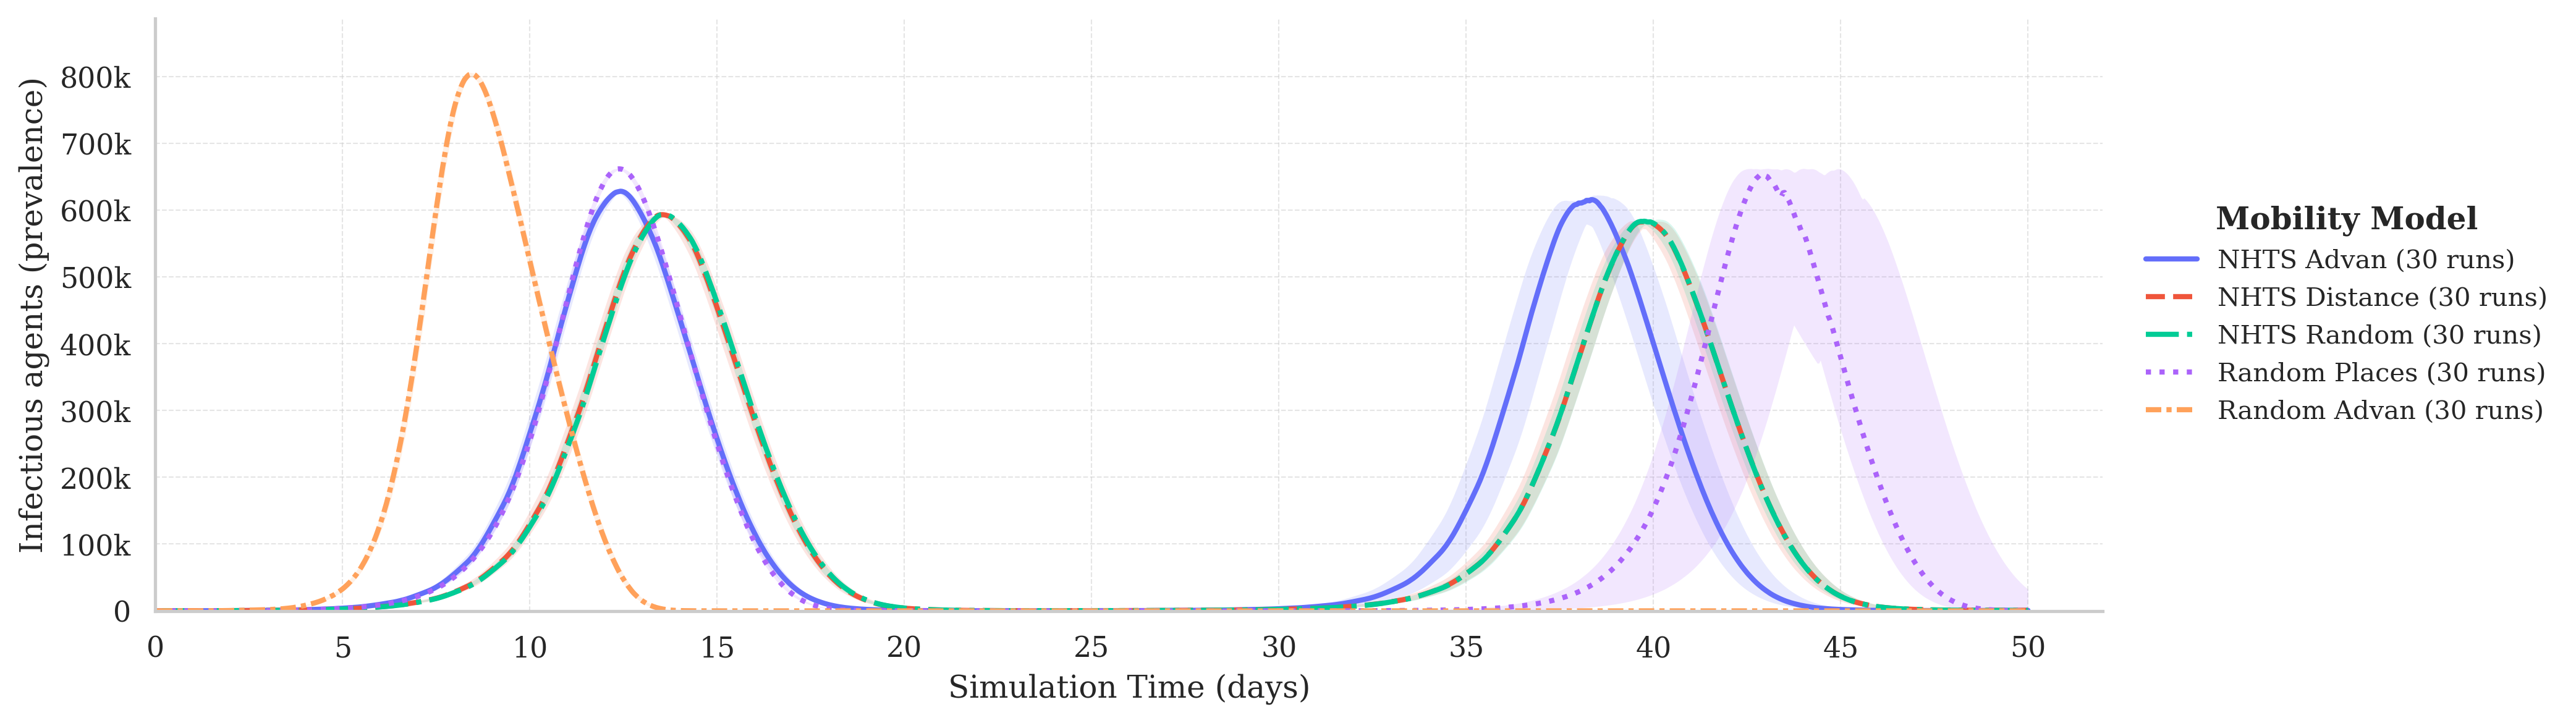

In [8]:
if sns is not None:
    sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.family': 'serif', 'font.size': 10, 'axes.labelsize': 12, 'legend.fontsize': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 300})
colors = {'NHTS Advan': '#636EFA', 'NHTS Distance': '#EF553B', 'NHTS Random': '#00CC96',
          'Random Places': '#AB63FA', 'Random Advan': '#FFA15A'}
linestyles = {'NHTS Advan': '-', 'NHTS Distance': '--', 'NHTS Random': '-.',
              'Random Places': ':', 'Random Advan': (0, (3, 1, 1, 1))}


def style_axes(ax, x_max, y_max, legend_title):
    ax.set_xlabel('Simulation Time (days)')
    ax.set_ylabel('Infectious agents (prevalence)')
    ax.set_xlim(0, x_max + 2)
    ax.set_ylim(0, y_max * 1.1)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: '0' if x == 0 else (f'{x * 1e-3:.0f}k' if x >= 1000 else f'{x:.0f}')))
    legend = ax.legend(title=legend_title, frameon=False, loc='center left', bbox_to_anchor=(1.01, 0.5))
    legend.get_title().set_fontweight('bold')
    ax.grid(which='major', linestyle='--', linewidth=0.5, alpha=0.5)


fig, ax = plt.subplots(figsize=(14, 4))
y_max, x_max = 0, 0
for label, runs in data.items():
    inf = pd.concat([states['Infectious'] for states, _, _, _ in runs], axis=1)
    days = inf.index / TICKS_PER_DAY
    ax.plot(days, inf.median(axis=1), label=f'{label} ({inf.shape[1]} runs)', color=colors[label],
            linestyle=linestyles[label], linewidth=2.0)
    ax.fill_between(days, inf.quantile(0.025, axis=1), inf.quantile(0.975, axis=1), color=colors[label], alpha=0.15, linewidth=0)
    y_max, x_max = max(y_max, inf.max().max()), max(x_max, days.max())
style_axes(ax, x_max, y_max, 'Mobility Model')
plt.tight_layout()
plt.savefig('disease_outcomes.pdf', dpi=600, format='pdf', bbox_inches='tight')
plt.show()

## Fig. 3: NHTS Distance with power-law distance decay (one run per exponent)

,modularity
Exponent 2,0.42
Exponent 3,0.66
Exponent 4,0.76
Exponent 5,0.81


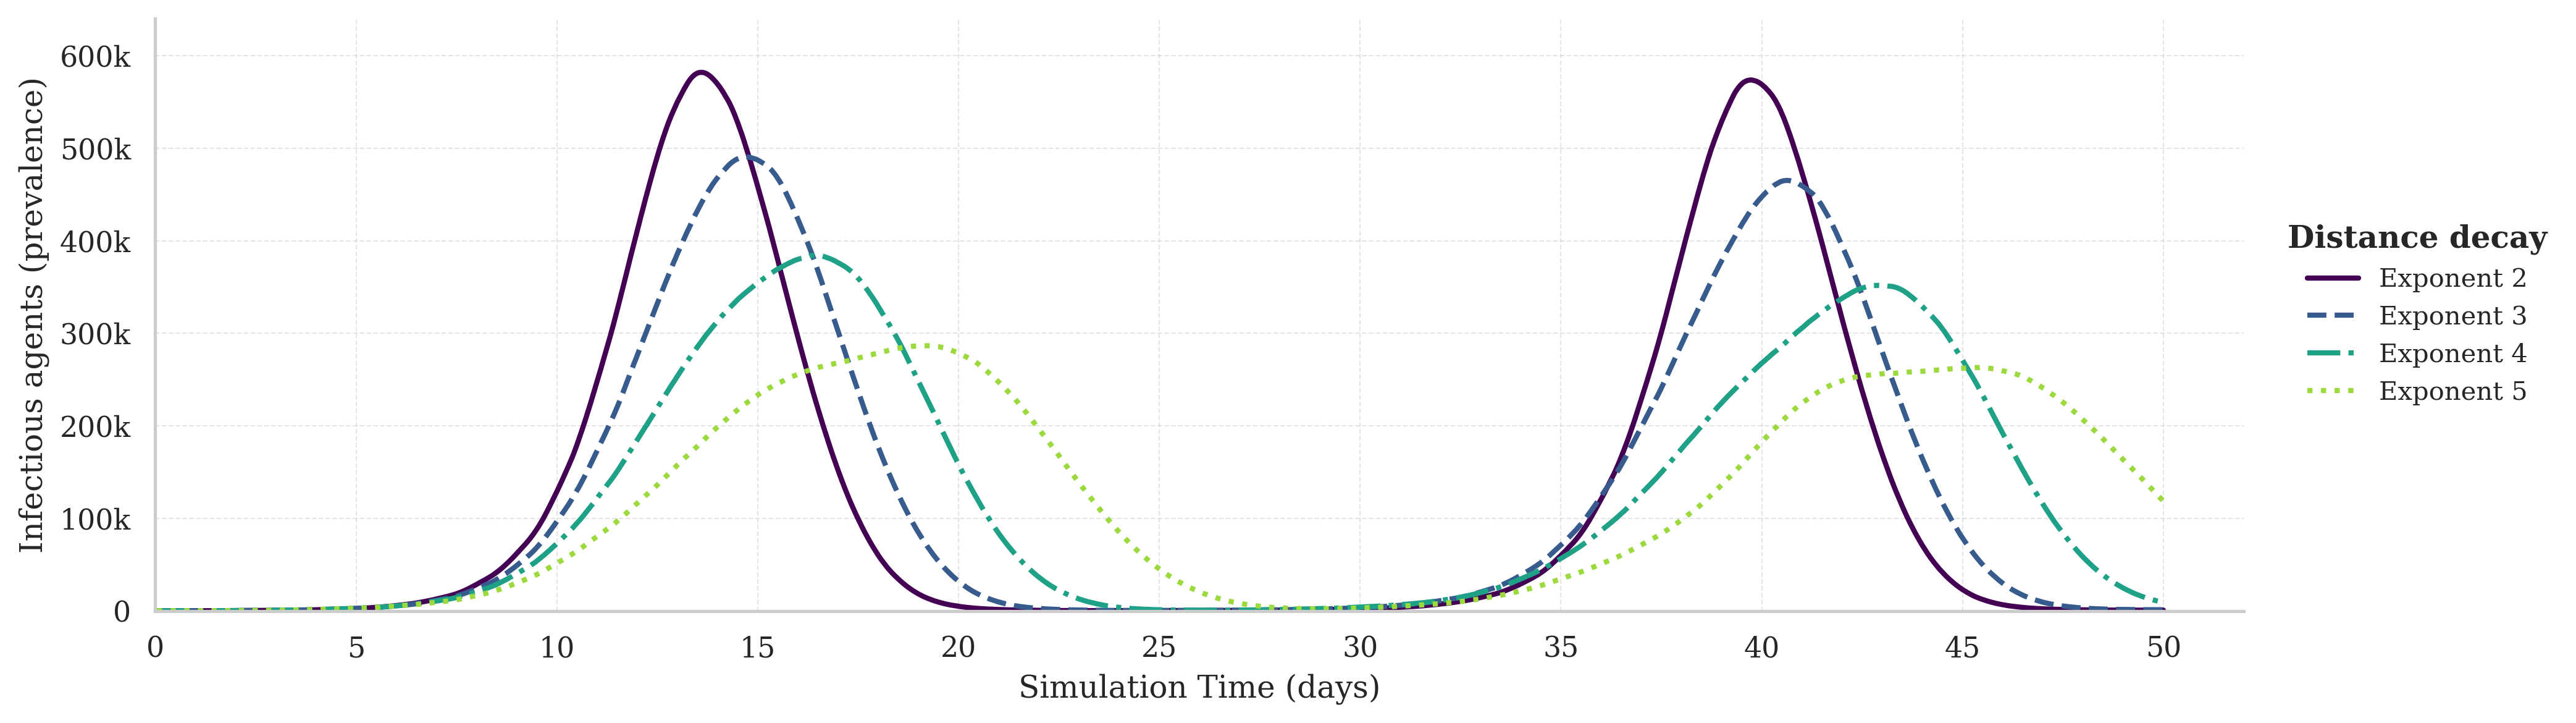

In [9]:
decay = {label: [load_run(r) for r in runs_of(DECAY_DIR, folder)] for label, folder in DECAY.items()}
modularity = pd.Series({label: runs[0][2]['modularity'] for label, runs in decay.items() if runs and runs[0][2]},
                       name='modularity').round(2)          # quoted in the text
save(modularity.to_frame(), 'decay_modularity.csv')
display(modularity.to_frame())

fig, ax = plt.subplots(figsize=(14, 4))
shades = plt.cm.viridis(np.linspace(0, 0.85, len(DECAY)))
styles = ['-', '--', '-.', ':']
y_max, x_max = 0, 0
for (label, runs), color, style in zip(decay.items(), shades, styles):
    if not runs:
        continue
    inf = pd.concat([states['Infectious'] for states, _, _, _ in runs], axis=1)
    days = inf.index / TICKS_PER_DAY
    ax.plot(days, inf.median(axis=1), label=label, color=color, linestyle=style, linewidth=2.0)
    y_max, x_max = max(y_max, inf.max().max()), max(x_max, days.max())
style_axes(ax, x_max, y_max, 'Distance decay')
plt.tight_layout()
plt.savefig('distance_decay.pdf', dpi=600, format='pdf', bbox_inches='tight')
plt.show()